[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wellingtonmnf/pos-graduacao-ia-ciencia-dados/blob/main/disciplinas/aprendizado-de-maquina/notebooks/unidade-02-classificacao/algoritmo-naive-bayes-gaussiano.ipynb)

##Algoritmo Gaussiano de Naive Bayes

Pense neste exemplo como um exercício de aprender a distinguir três tipos de flores — e a máquina vai fazer isso sozinha, com base em medidas.

Imagine que você tem uma coleção de 150 flores do gênero **Iris**, cada uma medida em quatro dimensões (comprimento e largura da pétala e da sépala). Você sabe a espécie de cada uma. O objetivo é: ensinar um algoritmo a identificar a espécie de uma flor nova, baseando-se apenas nessas medidas. Isso é exatamente o que chamamos de aprendizado supervisionado com classificação.

A documentação pode ser acessada no link:
https://scikit-learn.org/stable/modules/naive_bayes.html

Iris Dataset pode ser acessada em:
https://archive.ics.uci.edu/ml/datasets/iris

In [49]:
#importando as bibliotecas
from sklearn.datasets import load_iris # o dataset de flores
from sklearn.model_selection import train_test_split # para dividir os dados
#importando o modelo Naive Bayes
from sklearn.naive_bayes import GaussianNB # o algoritmo classificador

O `sklearn` (scikit-learn) é a biblioteca mais popular de machine learning em Python para iniciantes e profissionais. Pense nela como uma caixa de ferramentas com dezenas de algoritmos prontos para usar.

In [50]:
#carregando os dados
X, y = load_iris(return_X_y=True)

Aqui, `X` representa as features (as quatro medidas de cada flor) e `y` representa os rótulos (a espécie: 0, 1 ou 2). É como uma planilha onde `X` são as colunas de atributos e `y` é a coluna "resposta certa".

In [51]:
#separando a base de treino da validação
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

Esse é um dos passos mais importantes em qualquer projeto de Machine Learning. Você nunca deve testar o modelo com os mesmos dados que usou para treiná-lo — seria como dar ao aluno o gabarito antes da prova. Aqui, 50% dos dados (`test_size=0.5`) são reservados para o teste. O `random_state=0` garante que a divisão seja sempre a mesma toda vez que o código rodar — útil para reproduzir resultados.

In [52]:
#criando o classificador
gnb = GaussianNB()
#treinando o classificador
gnb.fit(X_train, y_train)

GaussianNB()

O `GaussianNB` é a implementação do Naive Bayes Gaussiano. Em uma analogia simples: o algoritmo aprende, para cada espécie, qual é a "faixa típica" de cada medida, assumindo que esses valores seguem uma distribuição em forma de sino (gaussiana). Depois, quando vê uma flor nova, calcula qual espécie tem maior probabilidade de ter gerado aquelas medidas.

In [53]:
#realizando as previsões
y_pred = gnb.predict(X_test)

Aqui o modelo usa o que aprendeu para prever a espécie das flores do conjunto de teste. O resultado `y_pred` é uma lista de 75 previsões (0, 1 ou 2), que você vai comparar com `y_test` (as respostas corretas).

##Como ver os resultados?

O código atual treina e prevê, mas não mostra nada. Veja como avaliar o desempenho do modelo:

Acurácia: 0.9466666666666667

Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        21
  versicolor       0.88      1.00      0.94        30
   virginica       1.00      0.83      0.91        24

    accuracy                           0.95        75
   macro avg       0.96      0.94      0.95        75
weighted avg       0.95      0.95      0.95        75



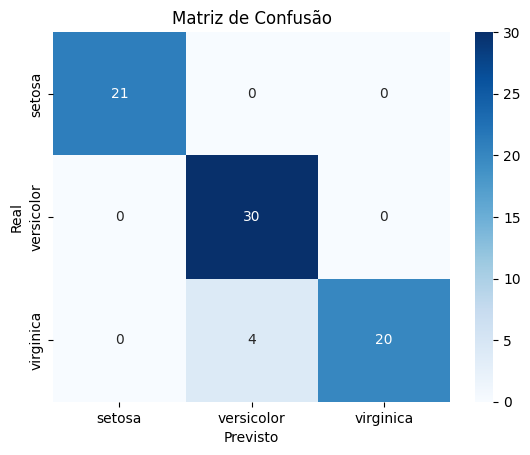

In [54]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Acurácia simples: % de acertos
print("Acurácia:", accuracy_score(y_test, y_pred))

# 2. Relatório detalhado por classe
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred,
      target_names=["setosa", "versicolor", "virginica"]))

# 3. Matriz de confusão (visual)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["setosa", "versicolor", "virginica"],
            yticklabels=["setosa", "versicolor", "virginica"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

A acurácia diz simplesmente quantos % o modelo acertou. O relatório de classificação vai mais fundo, mostrando precisão e recall por espécie. Já a matriz de confusão é especialmente poderosa: ela mostra exatamente onde o modelo errou — por exemplo, se confundiu `versicolor` com `virginica`.

##Um desafio para você 🎯

Após rodar o código com `test_size=0.5`, tente mudar esse valor para `0.2` (ou seja, usar 80% para treino). O que acontece com a acurácia? Isso vai te ajudar a desenvolver uma intuição muito importante sobre a relação entre quantidade de dados de treino e desempenho do modelo.